# Model exploration
Looks inside one trained model: the data it learned from, how inputs are transformed, which
features were kept, what drives its scores (SHAP), how well its probabilities match reality, and
how it compared with its shadow model in production.

Run after the Airflow pipeline. It only reads `model_bank/` and `datamart/`; it changes nothing.
Use the project's `.venv` kernel: it has the same scikit-learn and XGBoost versions as the
container, so the saved models load. Figures are saved to `notebooks/figures/` for slides.

The **Takeaway** notes under each chart describe `credit_model_2024_01_01_xgboost`. With another `VERSION`, the charts update but the notes do not.

In [1]:
import os
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import brier_score_loss, roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "model_bank").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
from utils import model_utils as mu

FIGURES = ROOT / "notebooks" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
config = mu.load_config()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def save(fig, name):
    fig.savefig(FIGURES / f"{VERSION}_{name}.png", dpi=200, bbox_inches="tight")


display(mu.read_registry())

C:\Users\Benedict\Documents\Coding Projects\MLE Assignment 2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,decision_date,model_version,promoted,model_type,challenger_oot_auc,challenger_oot_gini,champion_before,champion_oot_auc,reason
0,2024-01-01,credit_model_2024_01_01_xgboost,True,xgboost,0.8338,0.6677,NaN,NaN,first_model
1,2024-02-01,credit_model_2024_02_01_xgboost,True,xgboost,0.8616,0.7231,credit_model_2024_01_01_xgboost,0.8492,auc_gain
2,2024-03-01,credit_model_2024_03_01_xgboost,True,xgboost,0.8988,0.7976,credit_model_2024_02_01_xgboost,0.8860,auc_gain
3,2024-04-01,credit_model_2024_04_01_xgboost,False,xgboost,0.9017,0.8033,credit_model_2024_03_01_xgboost,0.8965,insufficient_auc_gain
4,2024-05-01,credit_model_2024_05_01_xgboost,True,xgboost,0.9110,0.8220,credit_model_2024_03_01_xgboost,0.8994,auc_gain
5,2024-06-01,credit_model_2024_06_01_xgboost,False,xgboost,0.8948,0.7897,credit_model_2024_05_01_xgboost,0.8951,insufficient_auc_gain
6,2024-07-01,credit_model_2024_07_01_xgboost,True,xgboost,0.8095,0.6191,credit_model_2024_05_01_xgboost,NaN,champion_features_unavailable
7,2024-08-01,credit_model_2024_08_01_xgboost,False,xgboost,0.8188,0.6376,credit_model_2024_07_01_xgboost,0.8145,insufficient_auc_gain
8,2024-09-01,credit_model_2024_09_01_xgboost,False,xgboost,0.8079,0.6159,credit_model_2024_07_01_xgboost,0.8033,insufficient_auc_gain
9,2024-10-01,credit_model_2024_10_01_xgboost,False,xgboost,0.7968,0.5936,credit_model_2024_07_01_xgboost,0.7930,insufficient_auc_gain


## 1. Pick a model
Change `VERSION` to any folder in `model_bank/`. The train, model-selection holdout and out-of-time (OOT) promotion rows are rebuilt with
the same code and random seed the pipeline used, so they are the exact rows the model saw.

In [2]:
# List every model in the model bank with its promotion decision.
# The project's model registry is model_bank/model_registry.csv (no MLflow server needed).
import json

rows = []
for folder in sorted((ROOT / mu.MODEL_BANK).glob("credit_model_*")):
    meta = json.load(open(folder / "metadata.json", encoding="utf-8"))
    rows.append({
        "model_version": meta["model_version"],
        "model_type": meta["model_type"],
        "runner_up (shadow)": meta["runner_up"],
        "trained_on_labels": " to ".join(meta["data"]["label_months"]),
        "gini_holdout": meta["metrics"]["gini_holdout"],
        "gini_oot": meta["metrics"]["gini_oot"],
        "calibrated": meta["calibration"]["applied"],
        "n_features": sum(len(v) for v in meta["features"].values()),
    })
models = pd.DataFrame(rows).merge(
    mu.read_registry()[["model_version", "promoted", "reason", "champion_before"]], on="model_version", how="left")
models["champion_now"] = models["model_version"] == mu.champion_as_of("9999-12-31")
display(models)

,model_version,model_type,runner_up (shadow),trained_on_labels,gini_holdout,gini_oot,calibrated,n_features,promoted,reason,champion_before,champion_now
0,credit_model_2024_01_01_xgboost,xgboost,logistic_regression,2023-07-01 to 2024-01-01,0.6695,0.6677,False,55,True,first_model,NaN,False
1,credit_model_2024_02_01_xgboost,xgboost,logistic_regression,2023-07-01 to 2024-02-01,0.6418,0.7231,False,54,True,auc_gain,credit_model_2024_01_01_xgboost,False
2,credit_model_2024_03_01_xgboost,xgboost,logistic_regression,2023-07-01 to 2024-03-01,0.6656,0.7976,False,50,True,auc_gain,credit_model_2024_02_01_xgboost,False
3,credit_model_2024_04_01_xgboost,xgboost,logistic_regression,2023-07-01 to 2024-04-01,0.7044,0.8033,False,49,False,insufficient_auc_gain,credit_model_2024_03_01_xgboost,False
4,credit_model_2024_05_01_xgboost,xgboost,logistic_regression,2023-07-01 to 2024-05-01,0.6710,0.8220,False,45,True,auc_gain,credit_model_2024_03_01_xgboost,False
5,credit_model_2024_06_01_xgboost,xgboost,logistic_regression,2023-07-01 to 2024-06-01,0.7250,0.7897,True,48,False,insufficient_auc_gain,credit_model_2024_05_01_xgboost,False
6,credit_model_2024_07_01_xgboost,xgboost,logistic_regression,2023-07-01 to 2024-07-01,0.5944,0.6191,False,37,True,champion_features_unavailable,credit_model_2024_05_01_xgboost,True
7,credit_model_2024_08_01_xgboost,xgboost,logistic_regression,2023-07-01 to 2024-08-01,0.6506,0.6376,False,37,False,insufficient_auc_gain,credit_model_2024_07_01_xgboost,False
8,credit_model_2024_09_01_xgboost,xgboost,logistic_regression,2023-07-01 to 2024-09-01,0.5988,0.6159,False,37,False,insufficient_auc_gain,credit_model_2024_07_01_xgboost,False
9,credit_model_2024_10_01_xgboost,xgboost,logistic_regression,2023-07-01 to 2024-10-01,0.6127,0.5936,False,37,False,insufficient_auc_gain,credit_model_2024_07_01_xgboost,False


> **Takeaway:** With monthly retraining, 13 models were trained (January 2024 to January 2025), and XGBoost won the model-selection holdout every month. Five became champion: January 2024 (first model), February, March and May 2024 (each beat the champion by at least 0.01 OOT AUC) and July 2024 (applicants stopped having clickstream, so the old champion lacked its inputs). The other eight were rejected by the 0.01 rule and ran in shadow. Calibration was kept for one model (June 2024, not promoted).

In [3]:
VERSION = "credit_model_2024_01_01_xgboost"

artefact = mu.load_artefact(VERSION)
train_date = artefact["data"]["train_date"]
data = mu.load_training_data(train_date)
train, holdout, oot = mu.split_train_holdout_oot(data, config)
features = artefact["features"]
base = artefact["base_pipeline"]          # the model before calibration
final = artefact["pipeline"]              # what inference uses
runner_up = artefact["runner_up"]         # the shadow model

print("model type:     ", artefact["model_type"], "-", artefact["selection_reason"])
print("runner-up:      ", runner_up["model_type"])
print("calibration:    ", "applied" if artefact["calibration"]["applied"] else "not applied")
print("rows:           ", artefact["data"]["rows"])
print("bad rate:       ", artefact["data"]["bad_rate"])
print("label months:   ", artefact["data"]["label_months"], "OOT:", artefact["data"]["oot_label_months"])
print("packages:       ", artefact["lineage"]["packages"])

labelled loans known on 2024-01-01: 3556, with features: 3556
model type:      xgboost - highest holdout Gini
runner-up:       logistic_regression
calibration:     not applied
rows:            {'train': 2054, 'holdout': 514, 'oot': 988}
bad rate:        {'train': 0.2848, 'holdout': 0.286, 'oot': 0.2804}
label months:    ['2023-07-01', '2024-01-01'] OOT: ['2023-12-01', '2024-01-01']
packages:        {'scikit-learn': '1.6.1', 'xgboost': '2.1.4', 'pandas': '2.1.4', 'numpy': '1.26.4'}


## 2. Default rate by label month
Each bar is the loans whose 6-month outcome was observed that month. The newest two months are
the out-of-time promotion set (OOT); everything before is split 80/20 into train and the
model-selection holdout.

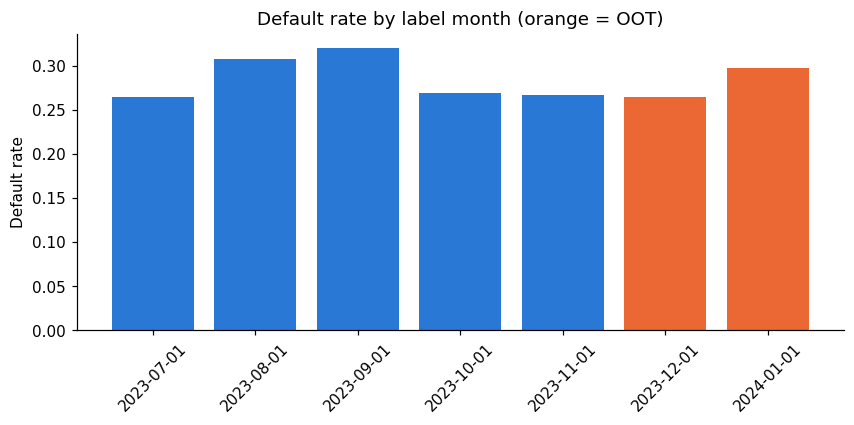

label_snapshot_date,2023-07-01,2023-08-01,2023-09-01,2023-10-01,2023-11-01,2023-12-01,2024-01-01
mean,0.264,0.307,0.32,0.269,0.267,0.265,0.297
size,530.000,501.000,506.00,510.000,521.000,517.000,471.000


In [4]:
by_month = data.groupby("label_snapshot_date")["label"].agg(["mean", "size"])
is_oot = by_month.index.isin(artefact["data"]["oot_label_months"])
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_month.index, by_month["mean"], color=np.where(is_oot, "#eb6834", "#2a78d6"))
ax.set(title="Default rate by label month (orange = OOT)", ylabel="Default rate")
ax.tick_params(axis="x", rotation=45)
save(fig, "default_rate_by_month")
plt.show()
display(by_month.round(3).T)

> **Takeaway:** The default rate stays between 26% and 32% in every label month, with about 500 loans each, so no month is unusual. The two OOT months (26.5% and 29.7%) look like the training months.

## 3. Transformations
Money columns are heavily skewed: a few very large values. Logistic regression uses their
`log1p` version (log of 1 + value), which pulls the long tail in; XGBoost uses raw values because
trees only care about order. Inside the model pipeline, numbers are filled with the training
median and standardised (logistic regression only), flags are filled with the most common value,
and categories are one-hot encoded with "Unknown" for missing.

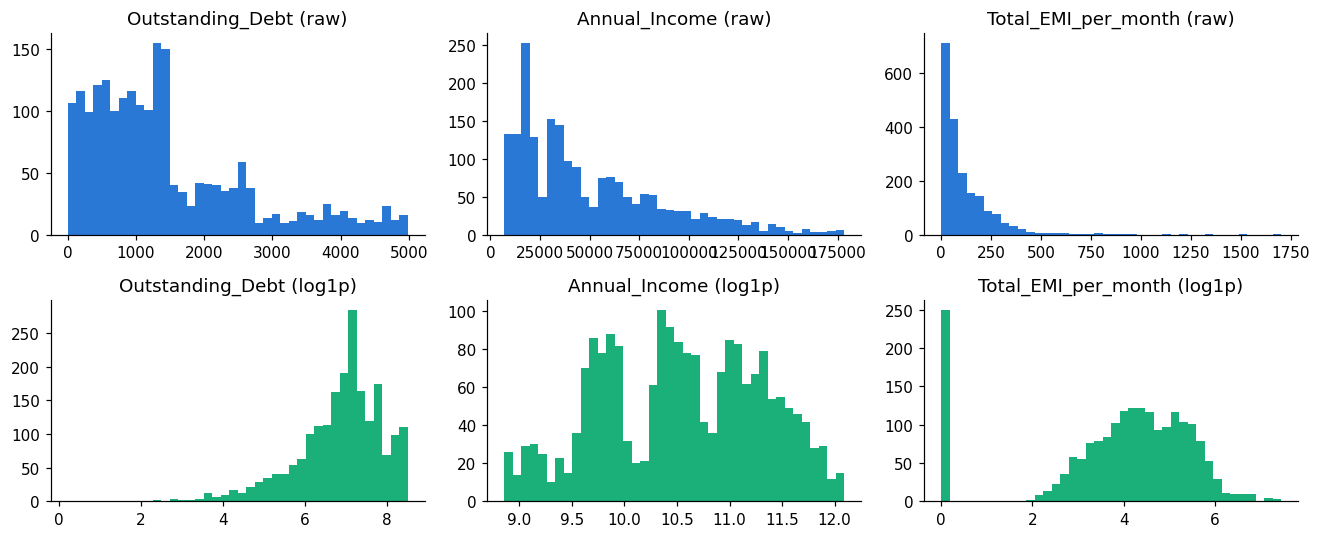

In [5]:
money = ["Outstanding_Debt", "Annual_Income", "Total_EMI_per_month"]
fig, axes = plt.subplots(2, len(money), figsize=(12, 5))
for i, column in enumerate(money):
    values = pd.to_numeric(train[column], errors="coerce").dropna()
    axes[0, i].hist(values, bins=40, color="#2a78d6")
    axes[0, i].set_title(column + " (raw)")
    axes[1, i].hist(np.log1p(values.clip(lower=0)), bins=40, color="#1baf7a")
    axes[1, i].set_title(column + " (log1p)")
fig.tight_layout()
save(fig, "log_transform")
plt.show()

> **Takeaway:** Money columns have a long right tail: monthly EMI has a median of 67 but a maximum of 1,701 (skew 4.0). After `log1p`, annual income is almost symmetric (skew -0.1) and the others tip slightly the other way (about -1.1), which is still far more even. The logistic regression runner-up uses the log versions; this XGBoost model uses raw values, because trees only care about order.

In [6]:
# one applicant before and after the pipeline's preprocessing step
X_train = mu.prepare_X(train, features)
preprocess = base.named_steps["preprocess"]
names = [mu._readable(n) for n in preprocess.get_feature_names_out()]
after = pd.Series(np.asarray(preprocess.transform(X_train.iloc[[0]]), dtype=float)[0], index=names)

before = X_train.iloc[0]
example = [c for c in features["numeric"][:5] + features["categorical"][:2]]
display(pd.DataFrame({"raw value": before[example]}))
display(after[[n for n in names if any(n.startswith(c) for c in example)]].round(3).to_frame("model input"))

,raw value
Age,32.0
Annual_Income,53320.98
Num_Bank_Accounts,7.0
Num_Credit_Card,6.0
Interest_Rate,20.0
Occupation,Journalist
Credit_Mix,Standard


,model input
Age,32.00
Annual_Income,53320.98
Num_Bank_Accounts,7.00
Num_Credit_Card,6.00
Interest_Rate,20.00
Occupation_Accountant,0.00
Occupation_Architect,0.00
Occupation_Developer,0.00
Occupation_Doctor,0.00
Occupation_Engineer,0.00


> **Takeaway:** For this XGBoost model, numbers pass through unchanged (trees only use order, and a missing value stays missing so the model can learn which way it should push). Only categories change: `Occupation` becomes 16 columns with a single 1. The logistic regression runner-up would also fill missing values with the training median and scale every number.

In [7]:
missing = X_train.isna().mean().sort_values(ascending=False).head(10)
display(missing.round(3).to_frame("share missing in train"))

,share missing in train
fe_5_mean,0.203
fe_9_mean,0.203
fe_3_mean,0.203
fe_4_mean,0.203
fe_2_mean,0.203
fe_6_mean,0.203
fe_7_mean,0.203
fe_8_mean,0.203
fe_1_mean,0.203
fe_10_mean,0.203


> **Takeaway:** The clickstream averages are missing for 20.3% of training loans: applicants with no browsing history before they applied. XGBoost learns which way a missing value should push; logistic regression fills it with the training median.

## 4. Feature selection
Information value (IV) measures how well one feature separates defaulters from non-defaulters on
the training split (higher is better: below 0.02 not useful, 0.1 to 0.3 medium, above 0.3 strong).
Weak features are dropped, and of two near-duplicate features (Spearman correlation above 0.9)
the one with lower IV is dropped.

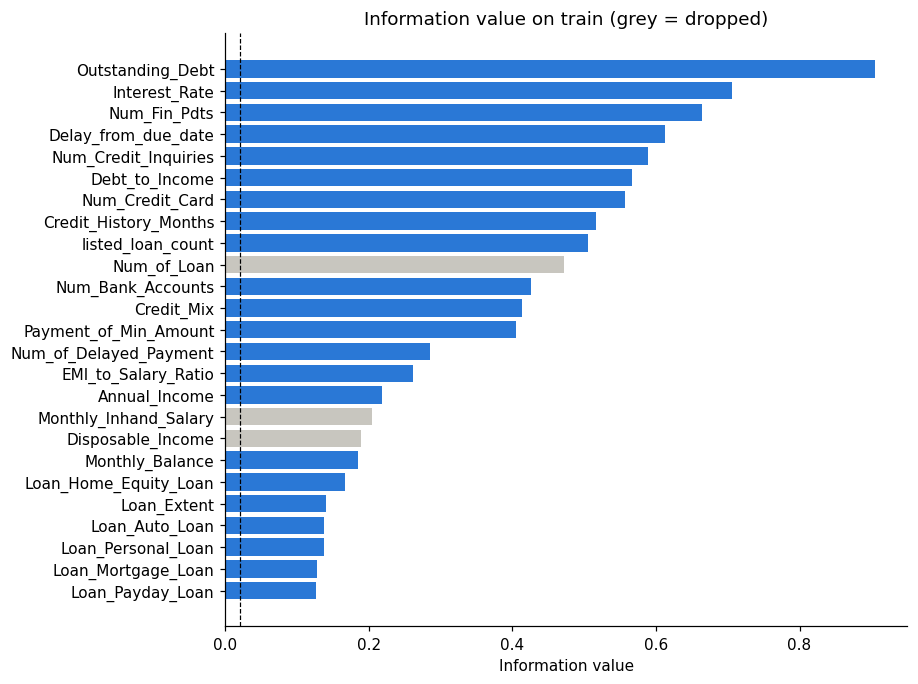

,feature,information_value,dropped
9,Num_of_Loan,0.4723,duplicate of listed_loan_count
16,Monthly_Inhand_Salary,0.2046,duplicate of Annual_Income
17,Disposable_Income,0.1896,duplicate of Annual_Income
58,fe_18_mean,0.0189,weak
59,fe_17_mean,0.0179,weak
60,fe_20_mean,0.0137,weak
61,fe_14_mean,0.0124,weak
62,interest_rate_invalid,0.0023,weak
63,num_credit_inquiries_invalid,0.0018,weak
64,annual_income_invalid,0.0014,weak


In [8]:
report = pd.DataFrame(artefact["feature_report"])
top = report.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top["feature"], top["information_value"],
        color=np.where(top["dropped"] == "", "#2a78d6", "#c8c6bf"))
ax.axvline(config["training"]["min_information_value"], color="black", linestyle="--", linewidth=0.8)
ax.set(title="Information value on train (grey = dropped)", xlabel="Information value")
save(fig, "information_value")
plt.show()
display(report[report["dropped"] != ""].round(4))

> **Takeaway:** 18 of 73 candidate features were dropped: 15 as weak (mostly the `*_invalid` flags and four clickstream averages, information value below 0.02) and 3 as duplicates (`Num_of_Loan` of `listed_loan_count`; `Monthly_Inhand_Salary` and `Disposable_Income` of `Annual_Income`). The strongest single features are `Outstanding_Debt` (0.90), `Interest_Rate` (0.71) and `Num_Fin_Pdts` (0.66).

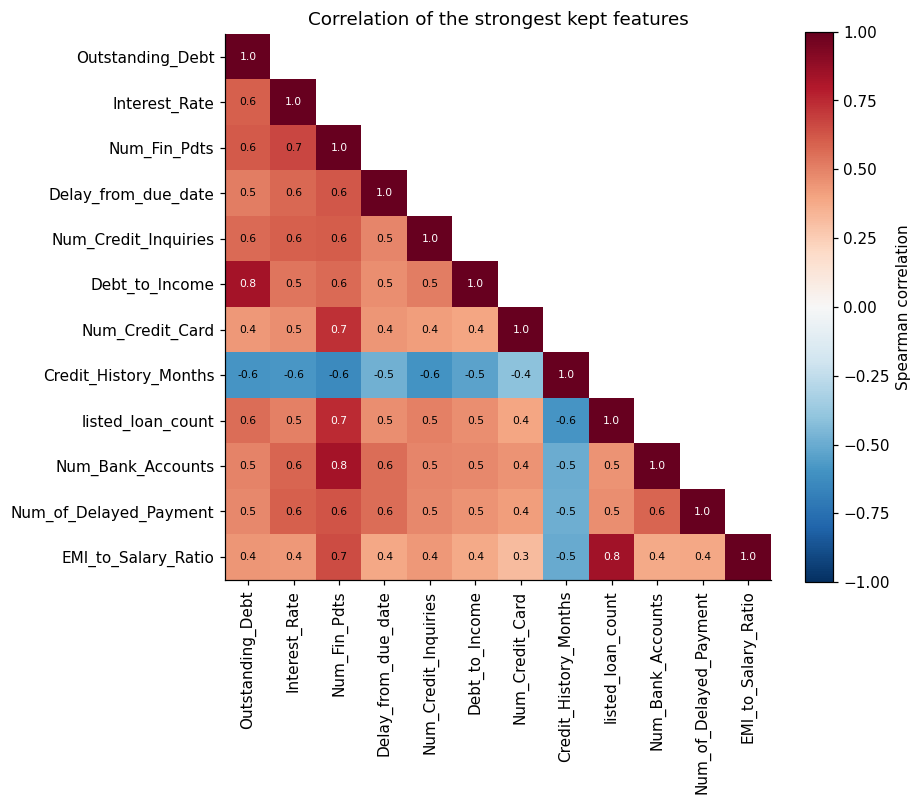

In [9]:
kept_numeric = [c for c in report.loc[report["dropped"] == "", "feature"] if c in features["numeric"]][:12]
corr = train[kept_numeric].apply(pd.to_numeric, errors="coerce").corr(method="spearman")
# keep the lower triangle and the diagonal: each pair once, no mirror image;
# the diagonal of 1.0 is each feature against itself
corr = corr.where(np.tril(np.ones(corr.shape, dtype=bool)))
fig, ax = plt.subplots(figsize=(8, 6.5))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
fig.colorbar(image, ax=ax, label="Spearman correlation")
for (i, j), value in np.ndenumerate(corr.values):
    if not np.isnan(value):
        ax.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=7,
                color="white" if abs(value) > 0.7 else "black")
ax.set_title("Correlation of the strongest kept features")
save(fig, "correlation")
plt.show()

> **Takeaway:** Most kept features are moderately related (0.4 to 0.7): customers with more financial products also have more inquiries and higher rates. The three strongest pairs, `Debt_to_Income` with `Outstanding_Debt` (0.83), `Num_Bank_Accounts` with `Num_Fin_Pdts` (0.83) and `EMI_to_Salary_Ratio` with `listed_loan_count` (0.84), stay below the 0.9 pruning line. A longer credit history moves the other way (about -0.6).

## 5. Model comparison
Gini = 2 x AUC - 1 (higher is better). A big drop from train to the holdout means the model
memorised its training data (overfitting). The model type is picked on the model-selection holdout; OOT is not
reported.

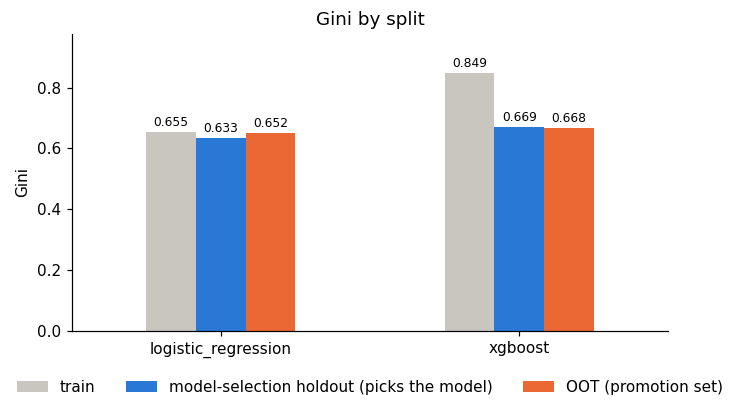

,gini_train,gini_holdout,gini_oot
logistic_regression,0.655,0.633,0.652
xgboost,0.849,0.670,0.668


In [10]:
scores = pd.DataFrame({t: c["scores"] for t, c in artefact["candidates"].items()}).T
gini = scores[["gini_train", "gini_holdout", "gini_oot"]]
ax = gini.plot.bar(figsize=(7, 3.5), rot=0, color=["#c8c6bf", "#2a78d6", "#eb6834"])
for bars in ax.containers:  # print each bar's value on top of it
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.set(title="Gini by split", ylabel="Gini", ylim=(0, gini.values.max() * 1.15))
ax.legend(["train", "model-selection holdout (picks the model)", "OOT (promotion set)"],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
save(ax.figure, "model_comparison")
plt.show()
display(gini.round(3))

> **Takeaway:** XGBoost wins the model-selection holdout by 0.036 (0.670 vs 0.633), more than the 0.01 tie-break, so it is chosen. It scores 0.849 on its own training loans, a sign it memorises part of them; logistic regression drops much less (0.655 to 0.633). OOT agrees (0.668 vs 0.652) but never chooses the model type. Before the split was made reproducible, the same comparison looked like a tie (0.597 vs 0.596): a 514-loan holdout moves by about 0.05 depending on which loans land in it.

## 6. What drives the score: SHAP
SHAP splits each applicant's score into one push per input, measured from the average applicant
(on the log-odds scale). Positive pushes towards default. 6a gives the big picture per original
feature, 6b shows the direction of each push, 6c lists the individual model columns, and 6d checks which features the model actually needs for accuracy.

In [11]:
def explain(pipeline, background, rows):
    """SHAP values for the model inside a pipeline, with readable feature names."""
    preprocess, model = pipeline.named_steps["preprocess"], pipeline.named_steps["model"]
    names = [mu._readable(n) for n in preprocess.get_feature_names_out()]
    matrix = pd.DataFrame(np.asarray(preprocess.transform(rows), dtype=float), columns=names)
    if hasattr(model, "coef_"):
        reference = np.asarray(preprocess.transform(background), dtype=float)
        explainer = shap.LinearExplainer(model, reference)
    else:
        explainer = shap.TreeExplainer(model)
    return explainer(matrix)


X_oot = mu.prepare_X(oot, features)
shap_values = explain(base, X_train, X_oot)
print('SHAP values:', shap_values.values.shape, '(applicants x model columns)')

SHAP values: (988, 83) (applicants x model columns)


### 6a. By original feature
One-hot encoding splits a category into one column per level (`Spending_Behaviour_High`,
`Spending_Behaviour_Low`, ...), and the clickstream averages are 16 to 20 separate columns, so each
piece looks small. SHAP values add up exactly, so summing the pieces per applicant gives each
original feature's total push. Levels are always kept or dropped together; this chart only
changes how they are reported.

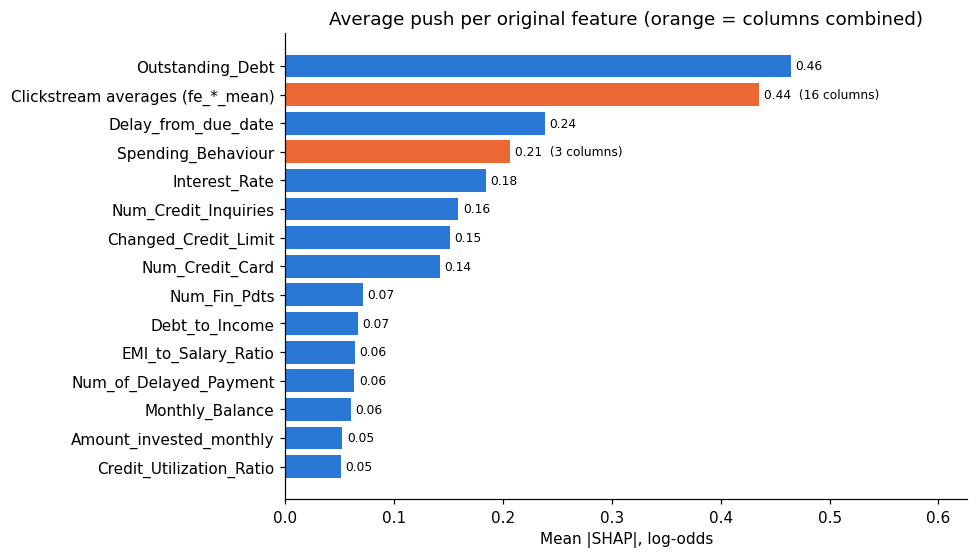

,mean |SHAP|,columns
Outstanding_Debt,0.464,1
Clickstream averages (fe_*_mean),0.436,16
Delay_from_due_date,0.238,1
Spending_Behaviour,0.207,3
Interest_Rate,0.184,1
Num_Credit_Inquiries,0.159,1
Changed_Credit_Limit,0.151,1
Num_Credit_Card,0.142,1
Num_Fin_Pdts,0.071,1
Debt_to_Income,0.067,1


In [12]:
def original_feature(column):
    """Map a model column back to the input it came from."""
    for category in features["categorical"]:
        if column.startswith(category + "_"):
            return category
    if column.startswith("fe_") and column.endswith("_mean"):
        return "Clickstream averages (fe_*_mean)"
    if column.startswith("Loan_") and column != "Loan_Extent":
        return "Loan type counts (Loan_*)"
    return column


per_applicant = pd.DataFrame(shap_values.values, columns=shap_values.feature_names)
grouped = per_applicant.T.groupby(original_feature).sum().T     # one total push per original feature
importance = grouped.abs().mean().sort_values(ascending=False)
pieces = pd.Series(shap_values.feature_names).map(original_feature).value_counts()

top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(top.index, top.values,
               color=["#eb6834" if pieces[name] > 1 else "#2a78d6" for name in top.index])
ax.bar_label(bars, labels=[f"{v:.2f}" + (f"  ({pieces[n]} columns)" if pieces[n] > 1 else "")
                           for n, v in zip(top.index, top.values)], fontsize=8, padding=3)
ax.set(title="Average push per original feature (orange = columns combined)",
       xlabel="Mean |SHAP|, log-odds", xlim=(0, top.max() * 1.35))
save(fig, "shap_importance_grouped")
plt.show()
display(importance.round(3).to_frame("mean |SHAP|").join(pieces.rename("columns")).head(20))

> **Takeaway:** `Outstanding_Debt` (0.46) and the clickstream averages taken together (0.44) are the biggest drivers, ahead of `Delay_from_due_date` (0.24) and `Spending_Behaviour` (0.21). Applicants have no clickstream from July 2024, so any model leaning on it had to be replaced then.

### 6b. Direction of each push
Every OOT applicant is a dot. Colour is the feature's value (red high, blue low); position is its
push (right = towards default).

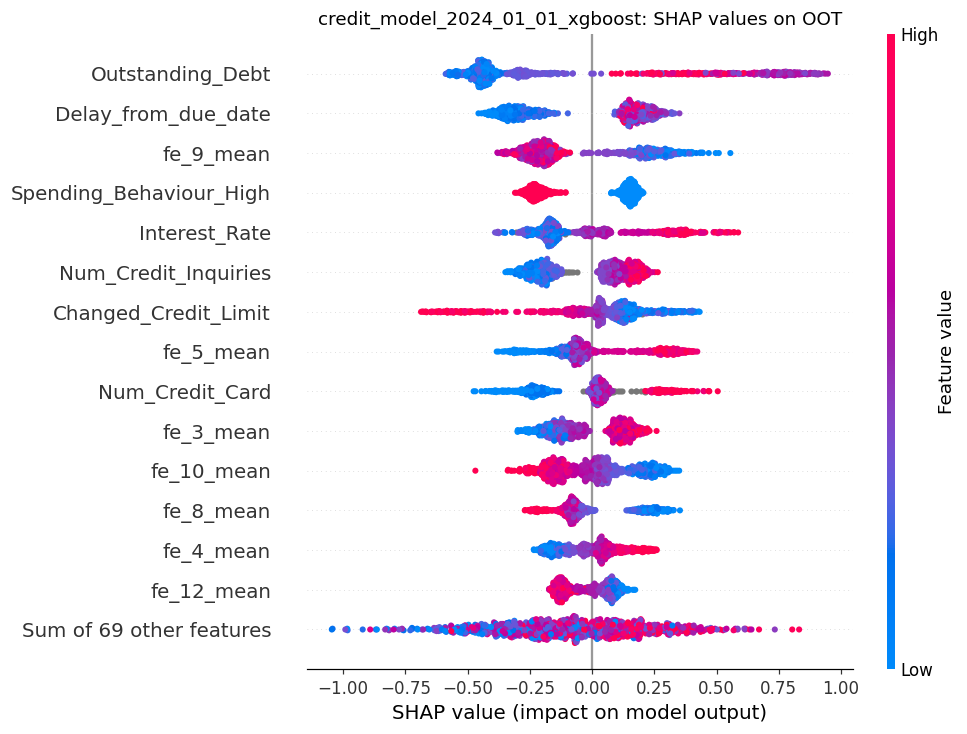

In [13]:
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title(f"{VERSION}: SHAP values on OOT")
save(plt.gcf(), "shap_beeswarm")
plt.show()

> **Takeaway:** Higher outstanding debt, more days past due, a higher interest rate and more credit inquiries push towards default, as expected. A larger change in credit limit pushes away from default. The clickstream averages go both ways (a high `fe_5_mean` raises risk, a high `fe_9_mean` lowers it); their meaning is not known because the columns are anonymised.

### 6c. Per model column
The same pushes per individual model column, before grouping.

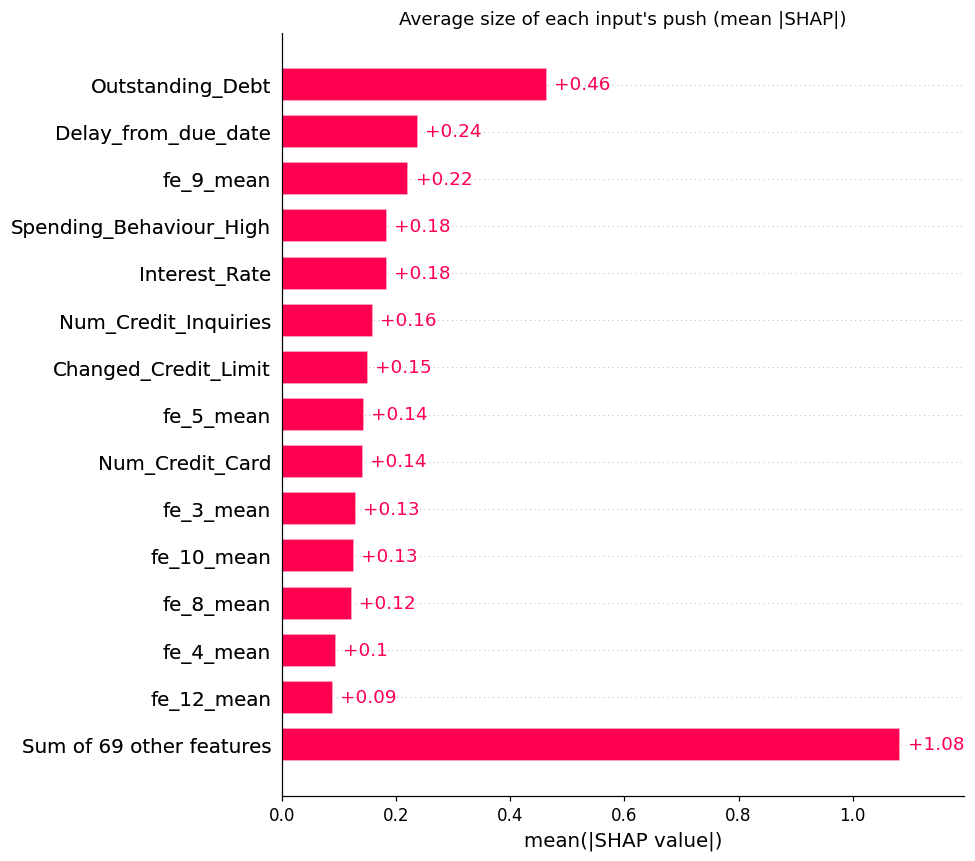

In [14]:
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Average size of each input's push (mean |SHAP|)")
save(plt.gcf(), "shap_importance")
plt.show()

> **Takeaway:** Per column, `Outstanding_Debt` leads. Category levels such as `Spending_Behaviour_High` and the 16 clickstream columns appear as separate, smaller bars, and the 69 smallest columns are summed into one row, which is why 6a groups them.

### 6d. What the model needs: permutation importance
SHAP shows how much a feature moves the score. Permutation importance asks a different question:
how much accuracy is lost when a feature's values are shuffled between OOT applicants, which breaks
its link to the outcome. Each feature (with all its one-hot columns, and the clickstream averages as
one group) is shuffled 20 times. A bigger drop means the model needs it more; a drop near zero
means other features already carry the same information.

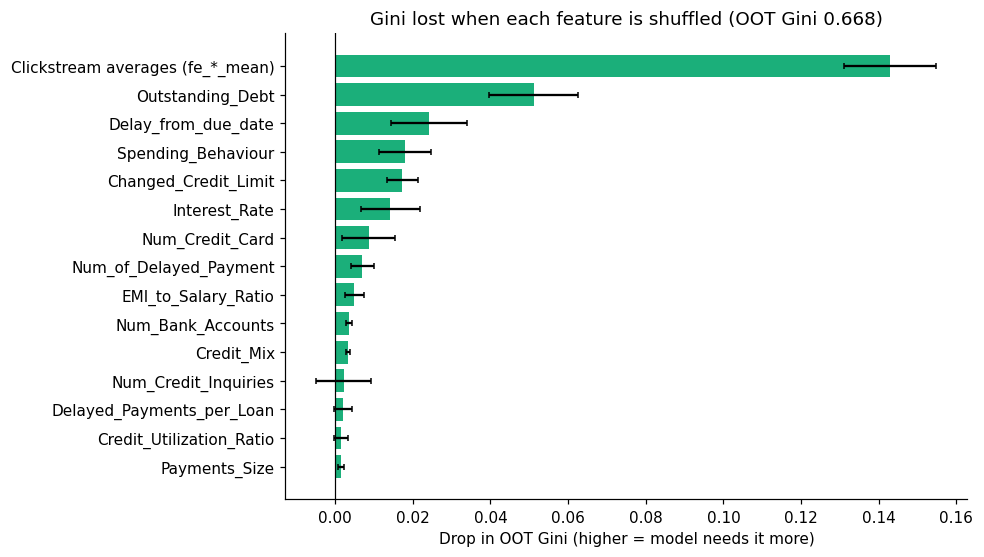

most needed:


,feature,gini_lost,spread,shap_rank
0,Clickstream averages (fe_*_mean),0.143,0.012,2
1,Outstanding_Debt,0.051,0.011,1
2,Delay_from_due_date,0.024,0.010,3
3,Spending_Behaviour,0.018,0.007,4
4,Changed_Credit_Limit,0.017,0.004,7
5,Interest_Rate,0.014,0.008,5
6,Num_Credit_Card,0.009,0.007,8
7,Num_of_Delayed_Payment,0.007,0.003,12
8,EMI_to_Salary_Ratio,0.005,0.002,11
9,Num_Bank_Accounts,0.004,0.001,23


least needed (shuffling barely hurts, or even helps):


,feature,gini_lost,spread,shap_rank
27,Payment_of_Min_Amount,-0.000,0.001,25
28,months12_to_annual_income_ratio,-0.000,0.001,24
29,Credit_History_Months,-0.001,0.001,18
30,Loan type counts (Loan_*),-0.001,0.001,17
31,Num_Fin_Pdts,-0.003,0.003,9


In [15]:
def gini_on(X):
    return 2 * roc_auc_score(oot["label"], base.predict_proba(X)[:, 1]) - 1


X_shuffle = X_oot.reset_index(drop=True)
inputs = pd.Series(X_shuffle.columns, index=X_shuffle.columns).map(original_feature)
baseline_gini = gini_on(X_shuffle)
rng = np.random.default_rng(0)

rows = []
for name, columns in inputs.groupby(inputs).groups.items():
    drops = []
    for _ in range(20):
        shuffled = X_shuffle.copy()
        shuffled[list(columns)] = X_shuffle[list(columns)].values[rng.permutation(len(X_shuffle))]
        drops.append(baseline_gini - gini_on(shuffled))
    rows.append({"feature": name, "gini_lost": np.mean(drops), "spread": np.std(drops)})
permutation = pd.DataFrame(rows).sort_values("gini_lost", ascending=False, ignore_index=True)
permutation["shap_rank"] = permutation["feature"].map({f: r + 1 for r, f in enumerate(importance.index)})

top = permutation.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top["feature"], top["gini_lost"], xerr=top["spread"], color="#1baf7a", capsize=2)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title=f"Gini lost when each feature is shuffled (OOT Gini {baseline_gini:.3f})",
       xlabel="Drop in OOT Gini (higher = model needs it more)")
save(fig, "permutation_importance")
plt.show()
print("most needed:")
display(permutation.head(15).round(3))
print("least needed (shuffling barely hurts, or even helps):")
display(permutation.tail(5).round(3))

> **Takeaway:** The model depends most on the clickstream averages: shuffling them costs 0.143 OOT Gini, almost three times `Outstanding_Debt` (0.051), because nothing else carries the same information. That is a risk, since these averages partly measure how long a customer has been around (the calendar effect). The rankings disagree where features overlap: `Num_Credit_Inquiries` is sixth by SHAP but costs only 0.002 when shuffled, because rates, cards and products tell a similar story. The new `Delayed_Payments_per_Loan` adds almost nothing to this model (0.002).

## 7. One applicant
The riskiest OOT applicant: the waterfall starts at the average score and adds each input's push.
The `reason_1` to `reason_3` columns in the predictions table are the biggest upward pushes.

predicted default probability 0.93; actually defaulted: 1


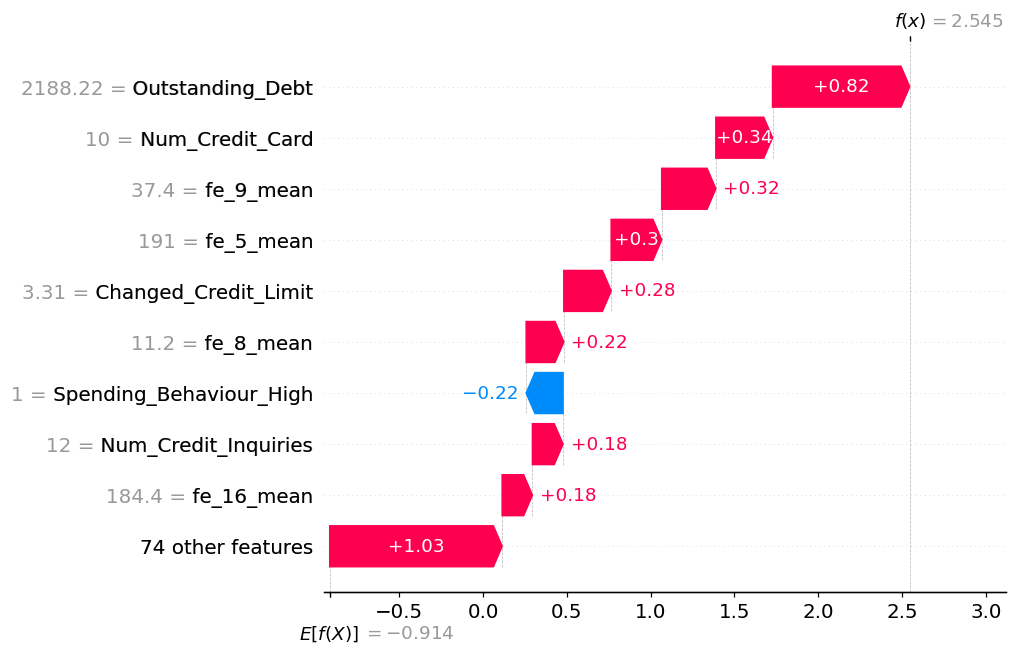

,reason_1,reason_2,reason_3
2033,Outstanding_Debt,Num_Credit_Card,fe_9_mean


In [16]:
risk = final.predict_proba(X_oot)[:, 1]
riskiest = int(np.argmax(risk))
print(f"predicted default probability {risk[riskiest]:.2f}; actually defaulted: {oot['label'].iloc[riskiest]}")
shap.plots.waterfall(shap_values[riskiest], max_display=10, show=False)
save(plt.gcf(), "shap_waterfall")
plt.show()
display(mu.reason_codes(base, X_oot.iloc[[riskiest]]))

> **Takeaway:** The riskiest OOT applicant was predicted 0.93 and did default. The biggest pushes were an outstanding debt of 2,188 (+0.82, inside the high-risk band shown in the next chart), 10 credit cards (+0.34) and two clickstream averages (`fe_9_mean` +0.32, `fe_5_mean` +0.30). The first three are the reason codes stored with that prediction.

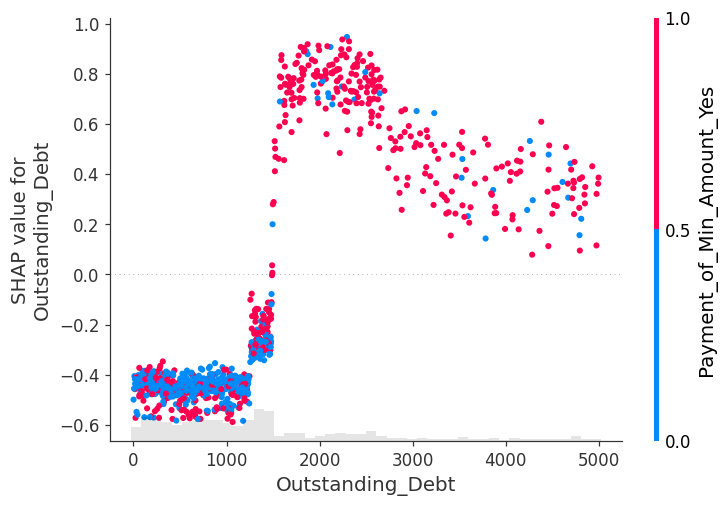

In [17]:
top_feature = shap_values.abs.mean(0).values.argmax()
shap.plots.scatter(shap_values[:, top_feature], color=shap_values, show=False)
save(plt.gcf(), "shap_dependence")
plt.show()

> **Takeaway:** XGBoost learned a hump that a straight-line model cannot draw. Below about 1,250 of outstanding debt the push is flat (about -0.45); it jumps between 1,250 and 1,600, peaks around 1,600 to 2,700 (+0.7 to +0.9) and falls back to +0.2 to +0.5 above 3,000. The raw default rates show the same shape, and this is a large part of why XGBoost beats logistic regression here.

## 8. The shadow model
The runner-up scored the same applicants in production without affecting decisions. Comparing
what each model relies on shows whether they learned the same story.

In [18]:
X_oot_shadow = mu.prepare_X(oot, runner_up["features"])
X_train_shadow = mu.prepare_X(train, runner_up["features"])
shadow_values = explain(runner_up["pipeline"], X_train_shadow, X_oot_shadow)

top_champion = pd.Series(np.abs(shap_values.values).mean(0), index=shap_values.feature_names).nlargest(10)
top_shadow = pd.Series(np.abs(shadow_values.values).mean(0), index=shadow_values.feature_names).nlargest(10)
display(pd.DataFrame({f"champion ({artefact['model_type']})": top_champion.index,
                      f"shadow ({runner_up['model_type']})": top_shadow.index}))

,champion (xgboost),shadow (logistic_regression)
0,Outstanding_Debt,EMI_to_Salary_Ratio
1,Delay_from_due_date,Changed_Credit_Limit
2,fe_9_mean,Interest_Rate
3,Spending_Behaviour_High,Num_Credit_Card
4,Interest_Rate,Num_Credit_Inquiries
5,Num_Credit_Inquiries,Spending_Behaviour_High
6,Changed_Credit_Limit,Payment_of_Min_Amount_No
7,fe_5_mean,Total_EMI_per_month_log1p
8,Num_Credit_Card,Outstanding_Debt_log1p
9,fe_3_mean,Spending_Behaviour_Low


> **Takeaway:** Both models use `Spending_Behaviour`, `Interest_Rate`, `Changed_Credit_Limit`, credit cards and inquiries. XGBoost leans on `Outstanding_Debt`, `Delay_from_due_date` and three clickstream averages; logistic regression leans on ratios such as `EMI_to_Salary_Ratio` and on log debt.

,gini,gini_pooled,credit_model_2024_01_01_logreg_runner_up
cohort_date,,,
2024-01-01,0.708,0.708,0.648


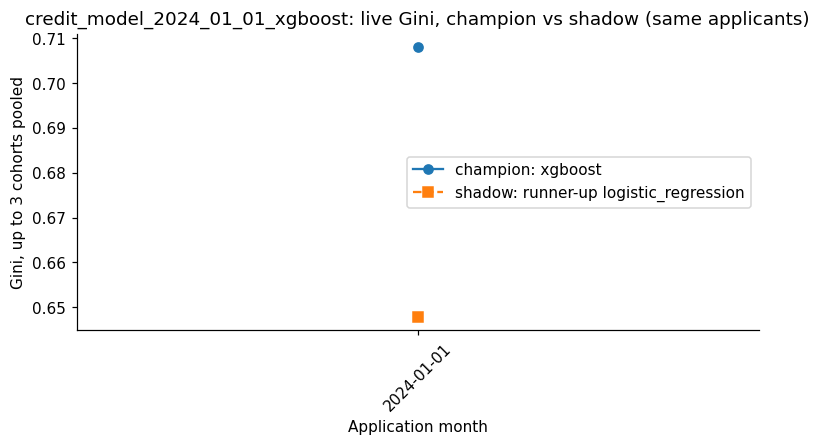

In [19]:
monitoring = pd.concat([pd.read_parquet(p) for p in sorted((ROOT / mu.MONITORING).glob("monitoring_*.parquet"))])
live = monitoring[monitoring["model_version"] == VERSION]
champion_live = live[live["metric_type"] == "performance"].set_index("cohort_date")[["gini", "gini_pooled"]]
shadow_live = live[live["metric_type"] == "shadow"].pivot_table(index="cohort_date", columns="shadow_model",
                                                               values="gini_pooled")
table = champion_live.join(shadow_live)
display(table.round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(table.index, table["gini_pooled"], marker="o", label=f"champion: {artefact['model_type']}")
for column in shadow_live.columns:
    kind = f"runner-up {runner_up['model_type']}" if column.endswith("_runner_up") else "rejected challenger " + column
    ax.plot(table.index, table[column], marker="s", linestyle="--", label=f"shadow: {kind}")
ax.set(title=f"{VERSION}: live Gini, champion vs shadow (same applicants)", ylabel="Gini, up to 3 cohorts pooled",
       xlabel="Application month")
ax.legend()
ax.tick_params(axis="x", rotation=45)
save(fig, "shadow_live_gini")
plt.show()

> **Takeaway:** This model was champion for one month. On January 2024 applicants it ranked defaulters better than its logistic regression runner-up in shadow (Gini 0.708 vs 0.648). The February 2024 XGBoost beat it by 0.013 OOT AUC and took over the next month.

## 9. Calibration
Do the probabilities match reality? Group OOT applicants into 10 bins by score and compare each
bin's average score with its actual default rate. Perfect calibration lies on the diagonal.
Platt scaling is fitted on the model-selection holdout and kept only if it lowers the Brier score on the
out-of-time promotion set
(lower is better).

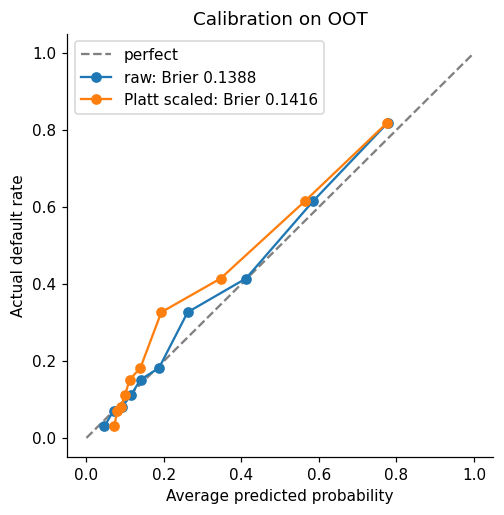

,saved in artefact
method,"platt (sigmoid) on holdout, kept if OOT Brier ..."
brier_oot_raw,0.1388
brier_oot_calibrated,0.1416
mean_prediction_oot_raw,0.2689
mean_prediction_oot_calibrated,0.2473
bad_rate_oot,0.2804
applied,False


In [20]:
platt = CalibratedClassifierCV(FrozenEstimator(base), method="sigmoid").fit(mu.prepare_X(holdout, features), holdout["label"])
raw = base.predict_proba(X_oot)[:, 1]
adjusted = platt.predict_proba(X_oot)[:, 1]

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
for name, probs in [("raw", raw), ("Platt scaled", adjusted)]:
    actual, predicted = calibration_curve(oot["label"], probs, n_bins=10, strategy="quantile")
    ax.plot(predicted, actual, marker="o",
            label=f"{name}: Brier {brier_score_loss(oot['label'], probs):.4f}")
ax.set(title="Calibration on OOT", xlabel="Average predicted probability", ylabel="Actual default rate")
ax.legend()
save(fig, "calibration_curve")
plt.show()
display(pd.Series(artefact["calibration"]).to_frame("saved in artefact"))

> **Takeaway:** The raw probabilities sit close to the diagonal: 26.9% predicted against 28.0% actual on OOT. Platt scaling made the Brier score worse (0.1388 to 0.1416, lower is better) and pulled the average down to 24.7%, so the pipeline kept the raw model.

## 10. Reason codes in production
How often each input was the top reason behind a score, across every month this model scored.

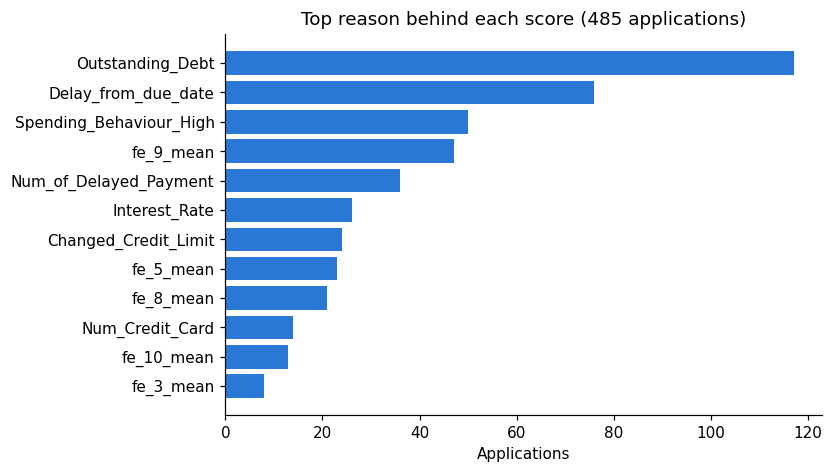

In [21]:
predictions = pd.concat([pd.read_parquet(p) for p in sorted((ROOT / mu.PREDICTIONS).glob("predictions_*.parquet"))])
mine = predictions[predictions["model_version"] == VERSION]
counts = mine["reason_1"].value_counts().head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(counts.index, counts.values, color="#2a78d6")
ax.set(title=f"Top reason behind each score ({len(mine)} applications)", xlabel="Applications")
save(fig, "reason_codes")
plt.show()

> **Takeaway:** Across the 485 January 2024 applications this model scored, the most common top reason is `Outstanding_Debt` (24%), then `Delay_from_due_date` (16%) and `Spending_Behaviour_High` (10%).